Surge classification (Decision Tree, Random Forest, XGBoost bonus) and k-NN ETA prediction.

## Step 1

In [1]:
import os
if not os.path.exists('/content/smart-ride-sharing-optimizer'):
    !git clone https://github.com/aasthakore-06/smart-ride-sharing-optimizer.git /content/smart-ride-sharing-optimizer
%cd /content/smart-ride-sharing-optimizer
!pip -q install xgboost
!git checkout -b radhika/models || git checkout radhika/models
os.makedirs('models', exist_ok=True)
os.makedirs('reports/figures', exist_ok=True)

Cloning into '/content/smart-ride-sharing-optimizer'...
remote: Enumerating objects: 47, done.
remote: Counting objects: 100% (47/47), done.
remote: Compressing objects: 100% (40/40), done.
remote: Total 47 (delta 12), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (47/47), 6.60 MiB | 3.45 MiB/s, done.
Resolving deltas: 100% (12/12), done.
/content/smart-ride-sharing-optimizer
Switched to a new branch 'radhika/models'


## Step 2: Config and imports

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib, json, time
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve,
    mean_absolute_error, mean_squared_error, r2_score)
from xgboost import XGBClassifier

SEED = 42
np.random.seed(SEED)

## Step 3: Surge classification data


In [3]:
d = pd.read_csv('data/processed/demand_labels.csv')
print(d.shape); print(d.high_demand.value_counts(normalize=True))

d['hour_sin'] = np.sin(2*np.pi*d['hour']/24)
d['hour_cos'] = np.cos(2*np.pi*d['hour']/24)
FEATS = ['pickup_cell_lat','pickup_cell_lon','hour','hour_sin','hour_cos']
X, y = d[FEATS], d['high_demand']

# 80:20 stratified split with SEED=42. If Astha pushes her own train/test files, load those instead.
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
print(Xtr.shape, Xte.shape)

(38495, 5)
high_demand
0    0.865489
1    0.134511
Name: proportion, dtype: float64
(30796, 5) (7699, 5)


## Step 4: Train Decision Tree, Random Forest, XGBoost
`class_weight='balanced'` because only about 13% of rows are high-demand.

In [4]:
neg, pos = (ytr==0).sum(), (ytr==1).sum()
models = {
    'Decision Tree': DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, class_weight='balanced', random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=150, max_depth=14, min_samples_leaf=5,
                                            class_weight='balanced', n_jobs=-1, random_state=SEED),
    'XGBoost (bonus)': XGBClassifier(n_estimators=250, max_depth=6, learning_rate=0.1,
                                     scale_pos_weight=neg/pos, eval_metric='logloss', random_state=SEED, n_jobs=-1),
}
rows, probs, preds = [], {}, {}
for name, m in models.items():
    t0 = time.time(); m.fit(Xtr, ytr); tt = time.time()-t0
    p = m.predict(Xte); pr = m.predict_proba(Xte)[:,1]
    preds[name], probs[name] = p, pr
    rows.append({'Model': name, 'Accuracy': accuracy_score(yte,p), 'Precision': precision_score(yte,p),
                 'Recall': recall_score(yte,p), 'F1': f1_score(yte,p), 'ROC-AUC': roc_auc_score(yte,pr),
                 'Train time (s)': round(tt,2)})
surge_results = pd.DataFrame(rows).round(3)
surge_results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Train time (s)
0,Decision Tree,0.564,0.213,0.834,0.340,0.738,0.17
1,Random Forest,0.720,0.269,0.631,0.377,0.764,4.40
2,XGBoost (bonus),0.710,0.283,0.756,0.412,0.814,2.70


## Step 5: Comparison plots (confusion matrix, ROC, feature importance)

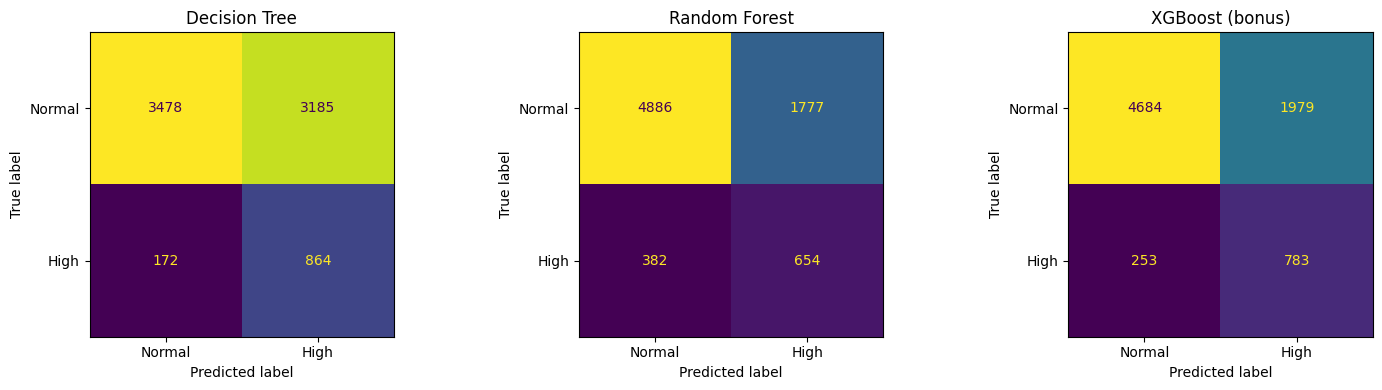

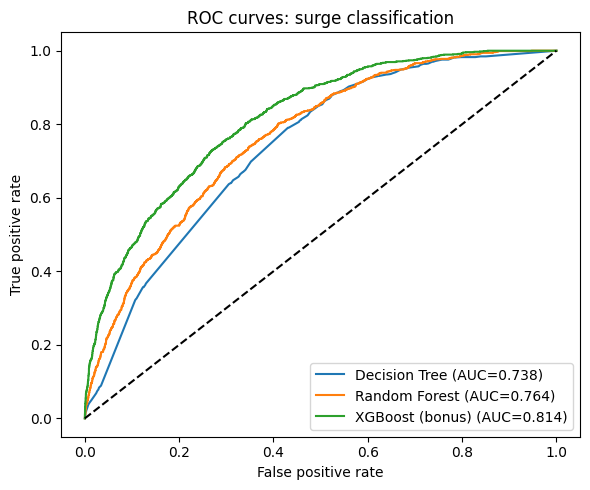

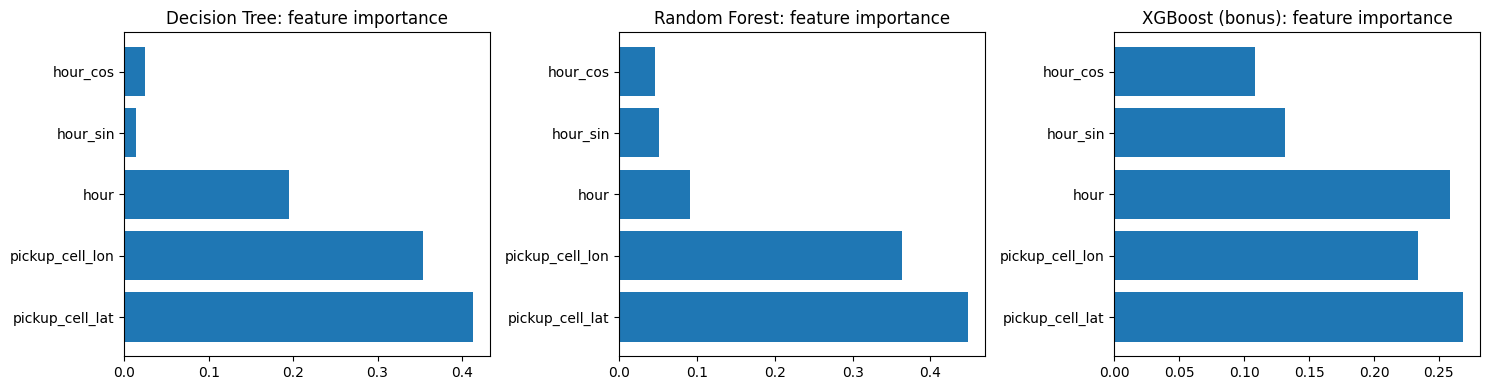

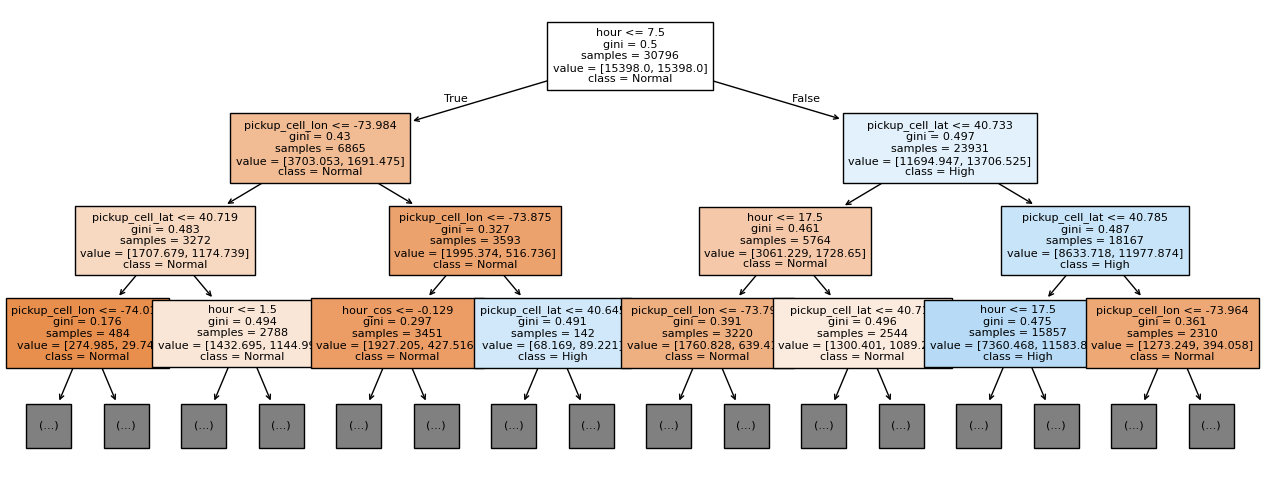

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15,4))
for a,(name,p) in zip(ax, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(yte,p), display_labels=['Normal','High']).plot(ax=a, colorbar=False)
    a.set_title(name)
plt.tight_layout(); plt.savefig('reports/figures/confusion_matrices.png', dpi=150); plt.show()

plt.figure(figsize=(6,5))
for name, pr in probs.items():
    fpr,tpr,_ = roc_curve(yte, pr); plt.plot(fpr,tpr,label=f"{name} (AUC={roc_auc_score(yte,pr):.3f})")
plt.plot([0,1],[0,1],'k--'); plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title('ROC curves: surge classification'); plt.legend(); plt.tight_layout()
plt.savefig('reports/figures/roc_curves.png', dpi=150); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15,4))
for a,(name,m) in zip(ax, models.items()):
    a.barh(FEATS, m.feature_importances_); a.set_title(f'{name}: feature importance')
plt.tight_layout(); plt.savefig('reports/figures/feature_importance.png', dpi=150); plt.show()

plt.figure(figsize=(16,6))
plot_tree(models['Decision Tree'], max_depth=3, feature_names=FEATS, class_names=['Normal','High'], filled=True, fontsize=8)
plt.savefig('reports/figures/decision_tree_top.png', dpi=150); plt.show()

## Step 6: k-NN ETA prediction


best k = 11 {1: np.float64(6.10022736241849), 3: np.float64(5.111469023687987), 5: np.float64(4.919105615812852), 7: np.float64(4.855408955936764), 9: np.float64(4.82725876569813), 11: np.float64(4.81619516410235), 15: np.float64(4.823439289804948), 21: np.float64(4.864437232527257), 31: np.float64(4.924659125868413), 41: np.float64(4.982421036496452)}


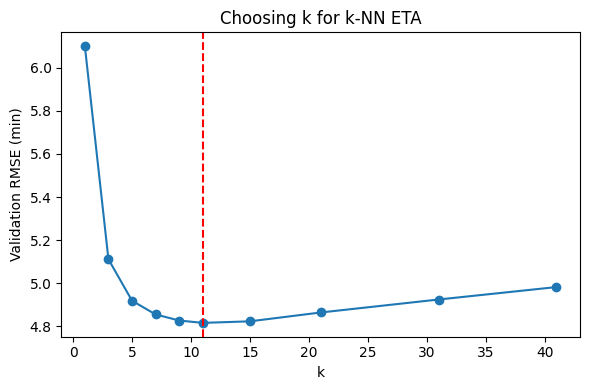

In [6]:
t = pd.read_csv('data/processed/cleaned_trips.csv')
ETA_FEATS = ['trip_distance','pickup_latitude','pickup_longitude','dropoff_latitude','dropoff_longitude','hour','day_of_week']
t = t[ETA_FEATS + ['duration_min']].dropna()
Xe, ye = t[ETA_FEATS], t['duration_min']
Xe_tr, Xe_te, ye_tr, ye_te = train_test_split(Xe, ye, test_size=0.2, random_state=SEED)
Xe_fit, Xe_val, ye_fit, ye_val = train_test_split(Xe_tr, ye_tr, test_size=0.2, random_state=SEED)

val_rmse = {}
for k in [1,3,5,7,9,11,15,21,31,41]:
    pipe = Pipeline([('sc', StandardScaler()), ('knn', KNeighborsRegressor(n_neighbors=k, weights='distance', n_jobs=-1))])
    pipe.fit(Xe_fit, ye_fit)
    val_rmse[k] = np.sqrt(mean_squared_error(ye_val, pipe.predict(Xe_val)))
best_k = min(val_rmse, key=val_rmse.get); print('best k =', best_k, val_rmse)

plt.figure(figsize=(6,4)); plt.plot(list(val_rmse), list(val_rmse.values()), 'o-'); plt.axvline(best_k, color='r', ls='--')
plt.xlabel('k'); plt.ylabel('Validation RMSE (min)'); plt.title('Choosing k for k-NN ETA'); plt.tight_layout()
plt.savefig('reports/figures/knn_k_selection.png', dpi=150); plt.show()

In [7]:
knn = Pipeline([('sc', StandardScaler()), ('knn', KNeighborsRegressor(n_neighbors=best_k, weights='distance', n_jobs=-1))])
knn.fit(Xe_tr, ye_tr)
base = DummyRegressor(strategy='mean').fit(Xe_tr, ye_tr)
eta_rows = []
for name, m in [('Mean baseline', base), (f'k-NN (k={best_k})', knn)]:
    p = m.predict(Xe_te)
    eta_rows.append({'Model': name, 'MAE (min)': mean_absolute_error(ye_te,p),
                     'RMSE (min)': np.sqrt(mean_squared_error(ye_te,p)), 'R2': r2_score(ye_te,p)})
eta_results = pd.DataFrame(eta_rows).round(3); eta_results

,Model,MAE (min),RMSE (min),R2
0,Mean baseline,7.531,10.551,-0.0
1,k-NN (k=11),2.941,4.714,0.8


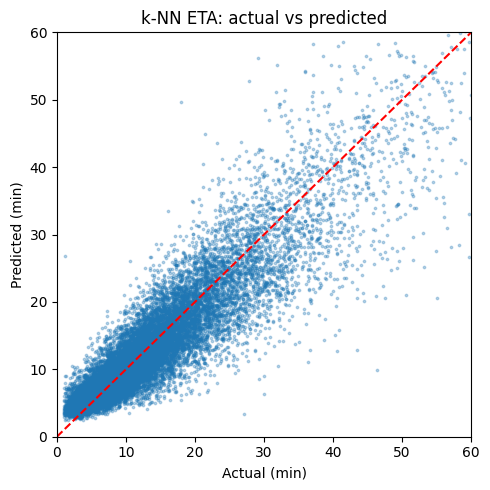

In [8]:
p = knn.predict(Xe_te)
plt.figure(figsize=(5,5)); plt.scatter(ye_te, p, s=3, alpha=0.3); plt.plot([0,60],[0,60],'r--')
plt.xlim(0,60); plt.ylim(0,60); plt.xlabel('Actual (min)'); plt.ylabel('Predicted (min)'); plt.title('k-NN ETA: actual vs predicted')
plt.tight_layout(); plt.savefig('reports/figures/knn_actual_vs_pred.png', dpi=150); plt.show()

## Step 7: Fare prediction (Linear Regression, plus Ridge and Random Forest for comparison)


trips without demand label: 0
                       Model  MAE ($)  RMSE ($)     R2
0          Linear Regression    0.715     3.170  0.914
1            Ridge (alpha=1)    0.715     3.170  0.914
2  Random Forest (reference)    0.497     3.022  0.922
is_weekend      -0.046485
high_demand     -0.030801
hour            -0.005898
day_of_week     -0.003706
duration_min     3.043260
trip_distance    7.486254
dtype: float64


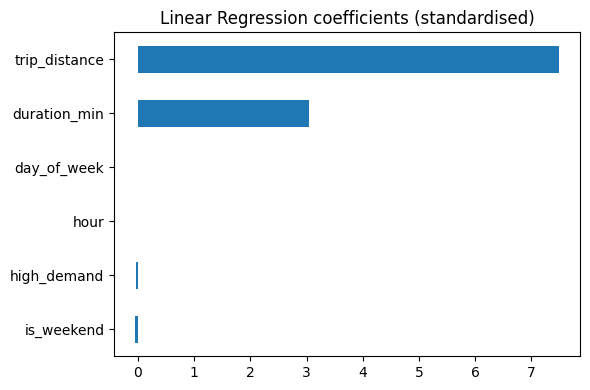

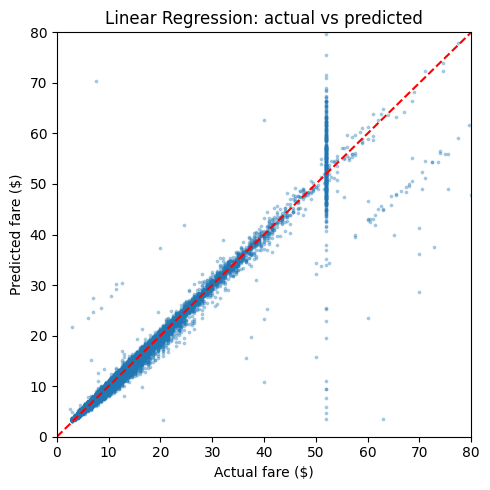

In [9]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor

trips = pd.read_csv('data/processed/cleaned_trips.csv')
lab = d[['pickup_cell_lat','pickup_cell_lon','hour','high_demand']]
f = trips.merge(lab, on=['pickup_cell_lat','pickup_cell_lon','hour'], how='left')
print('trips without demand label:', f.high_demand.isna().sum())
f['high_demand'] = f['high_demand'].fillna(0)
f['is_weekend'] = (f['day_of_week']>=5).astype(int)
FARE_FEATS = ['trip_distance','duration_min','hour','day_of_week','is_weekend','high_demand']
f = f[FARE_FEATS+['fare_amount']].dropna()
Xf, yf = f[FARE_FEATS], f['fare_amount']
Xf_tr, Xf_te, yf_tr, yf_te = train_test_split(Xf, yf, test_size=0.2, random_state=SEED)

fare_models = {
  'Linear Regression': Pipeline([('sc',StandardScaler()),('m',LinearRegression())]),
  'Ridge (alpha=1)':   Pipeline([('sc',StandardScaler()),('m',Ridge(alpha=1.0))]),
  'Random Forest (reference)': RandomForestRegressor(n_estimators=100, max_depth=14, min_samples_leaf=5, n_jobs=-1, random_state=SEED),
}
fr = []
for name, m in fare_models.items():
    m.fit(Xf_tr, yf_tr); p = m.predict(Xf_te)
    fr.append({'Model':name,'MAE ($)':mean_absolute_error(yf_te,p),'RMSE ($)':np.sqrt(mean_squared_error(yf_te,p)),'R2':r2_score(yf_te,p)})
fare_results = pd.DataFrame(fr).round(3); print(fare_results)

lr = fare_models['Linear Regression']
coef = pd.Series(lr.named_steps['m'].coef_, index=FARE_FEATS).sort_values()
print(coef)
plt.figure(figsize=(6,4)); coef.plot.barh(); plt.title('Linear Regression coefficients (standardised)'); plt.tight_layout()
plt.savefig('reports/figures/fare_coefficients.png', dpi=150); plt.show()

p = lr.predict(Xf_te)
plt.figure(figsize=(5,5)); plt.scatter(yf_te, p, s=3, alpha=0.3); plt.plot([0,80],[0,80],'r--')
plt.xlim(0,80); plt.ylim(0,80); plt.xlabel('Actual fare ($)'); plt.ylabel('Predicted fare ($)'); plt.title('Linear Regression: actual vs predicted')
plt.tight_layout(); plt.savefig('reports/figures/fare_actual_vs_pred.png', dpi=150); plt.show()

## Step 8: K-Means demand hotspots (location and time)
Elbow and silhouette to choose k, then clusters by pickup location. A time-of-day split shows how each hotspot's demand changes (the folium map layer for the app).

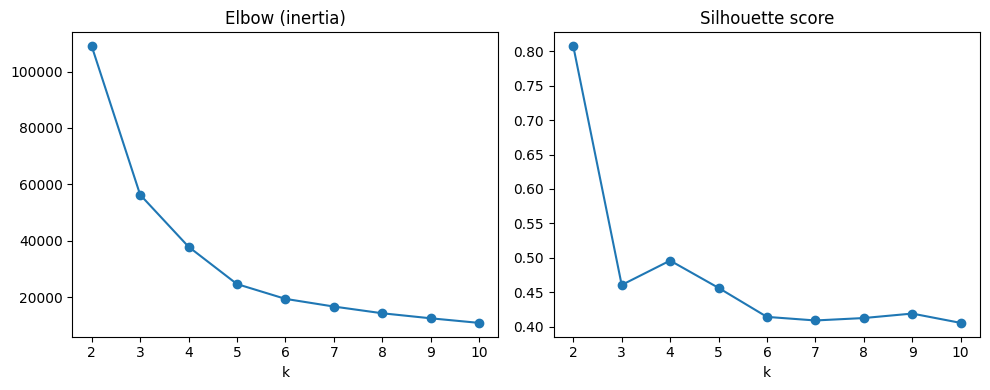

{2: np.float64(0.808), 3: np.float64(0.46), 4: np.float64(0.496), 5: np.float64(0.456), 6: np.float64(0.414), 7: np.float64(0.409), 8: np.float64(0.412), 9: np.float64(0.419), 10: np.float64(0.405)}


In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

geo = trips[['pickup_latitude','pickup_longitude','hour']].dropna()
geo = geo[(geo.pickup_latitude.between(40.55,40.95)) & (geo.pickup_longitude.between(-74.1,-73.7))]
G = geo[['pickup_latitude','pickup_longitude']].values
sc_geo = StandardScaler().fit(G); Gs = sc_geo.transform(G)
samp = np.random.RandomState(SEED).choice(len(Gs), size=min(10000,len(Gs)), replace=False)

inertia, sil = {}, {}
for k in range(2,11):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Gs)
    inertia[k] = km.inertia_; sil[k] = silhouette_score(Gs[samp], km.labels_[samp])
fig, ax = plt.subplots(1,2,figsize=(10,4))
ax[0].plot(list(inertia), list(inertia.values()), 'o-'); ax[0].set_title('Elbow (inertia)'); ax[0].set_xlabel('k')
ax[1].plot(list(sil), list(sil.values()), 'o-'); ax[1].set_title('Silhouette score'); ax[1].set_xlabel('k')
plt.tight_layout(); plt.savefig('reports/figures/kmeans_elbow_silhouette.png', dpi=150); plt.show()
print({k: round(v,3) for k,v in sil.items()})

         lat        lon  cluster  trips
0  40.760248 -73.977581        0  32359
1  40.646392 -73.784861        1   2108
2  40.769118 -73.873581        2   2957
3  40.715650 -73.996797        3  13793
4  40.783381 -73.960962        4  18662
5  40.741218 -73.991921        5  27484
period   Night  Morning  Midday  Evening  Late night
cluster                                             
0         2890     7856    7995    10381        3237
1          193      418     553      695         249
2          259      726     758      852         362
3         2634     2646    2738     3926        1849
4         1140     5925    5334     5064        1199
5         3701     6378    6017     8279        3109


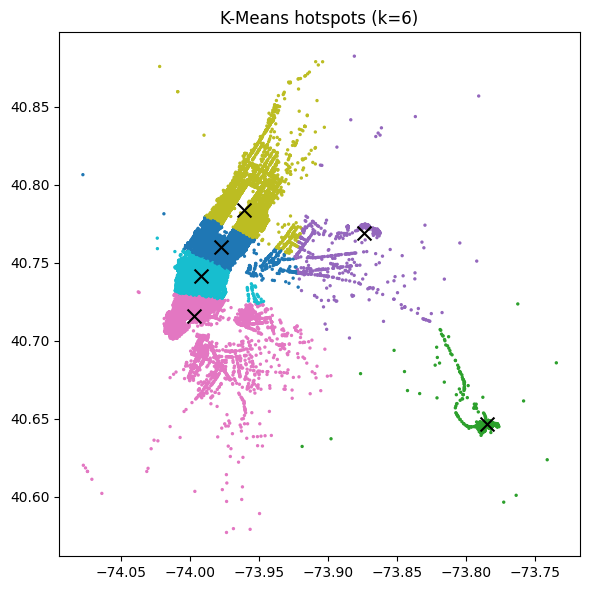

In [11]:
K = 6   # pick from the elbow/silhouette plots; change if your plots suggest another value
kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(Gs)
geo['cluster'] = kmeans.labels_
centers = pd.DataFrame(sc_geo.inverse_transform(kmeans.cluster_centers_), columns=['lat','lon'])
centers['cluster'] = range(K); centers['trips'] = geo.cluster.value_counts().sort_index().values
geo['period'] = pd.cut(geo.hour, [-1,5,11,16,21,23], labels=['Night','Morning','Midday','Evening','Late night'])
by_time = pd.crosstab(geo.cluster, geo.period)
print(centers); print(by_time)

plt.figure(figsize=(6,6)); plt.scatter(geo.pickup_longitude, geo.pickup_latitude, c=geo.cluster, s=2, cmap='tab10')
plt.scatter(centers.lon, centers.lat, c='k', marker='x', s=100); plt.title(f'K-Means hotspots (k={K})')
plt.tight_layout(); plt.savefig('reports/figures/kmeans_clusters.png', dpi=150); plt.show()

## Step 9: Best model per task

In [12]:
summary = pd.DataFrame([
  {'Task':'Surge classification','Best model':surge_results.sort_values('F1',ascending=False).iloc[0]['Model'],'Chosen by':'F1 / ROC-AUC'},
  {'Task':'Fare prediction','Best model':fare_results.sort_values('RMSE ($)').iloc[0]['Model'],'Chosen by':'RMSE / R2'},
  {'Task':'ETA estimate','Best model':f'k-NN (k={best_k})','Chosen by':'MAE / RMSE vs baseline'},
  {'Task':'Hotspots','Best model':f'K-Means (k={K})','Chosen by':'Elbow + silhouette'},
]); summary

,Task,Best model,Chosen by
0,Surge classification,XGBoost (bonus),F1 / ROC-AUC
1,Fare prediction,Random Forest (reference),RMSE / R2
2,ETA estimate,k-NN (k=11),MAE / RMSE vs baseline
3,Hotspots,K-Means (k=6),Elbow + silhouette


## Step 10: Save models

In [13]:
best_name = surge_results.sort_values('F1', ascending=False).iloc[0]['Model']
print('Best surge model by F1:', best_name)
joblib.dump(models['Random Forest'], 'models/surge_rf.joblib', compress=3)
joblib.dump(models['Decision Tree'], 'models/surge_dt.joblib', compress=3)
joblib.dump(models['XGBoost (bonus)'], 'models/surge_xgb.joblib', compress=3)
joblib.dump(knn, 'models/eta_knn.joblib', compress=3)
joblib.dump(fare_models['Linear Regression'], 'models/fare_linear.joblib', compress=3)
joblib.dump(fare_models['Ridge (alpha=1)'], 'models/fare_ridge.joblib', compress=3)
joblib.dump({'scaler': sc_geo, 'kmeans': kmeans}, 'models/hotspots_kmeans.joblib', compress=3)
centers.to_csv('reports/hotspot_centers.csv', index=False); by_time.to_csv('reports/hotspot_by_time.csv')
fare_results.to_csv('reports/fare_results.csv', index=False); summary.to_csv('reports/best_model_per_task.csv', index=False)
json.dump({'surge_features': FEATS, 'eta_features': ETA_FEATS, 'fare_features': FARE_FEATS, 'kmeans_k': K, 'best_k': int(best_k), 'seed': SEED},
          open('models/model_meta.json','w'), indent=2)
surge_results.to_csv('reports/surge_results.csv', index=False)
eta_results.to_csv('reports/eta_results.csv', index=False)
!ls -lh models reports

Best surge model by F1: XGBoost (bonus)
models:
total 15M
-rw-r--r-- 1 root root 6.3M Oct 16 15:15 eta_knn.joblib
-rw-r--r-- 1 root root 1.1K Oct 16 15:15 fare_linear.joblib
-rw-r--r-- 1 root root 1012 Oct 16 15:15 fare_ridge.joblib
-rw-r--r-- 1 root root  54K Oct 16 15:15 hotspots_kmeans.joblib
-rw-r--r-- 1 root root  471 Oct 16 15:15 model_meta.json
-rw-r--r-- 1 root root    1 Oct 16 15:13 README.md
-rw-r--r-- 1 root root  13K Oct 16 15:15 surge_dt.joblib
-rw-r--r-- 1 root root 7.9M Oct 16 15:15 surge_rf.joblib
-rw-r--r-- 1 root root 266K Oct 16 15:15 surge_xgb.joblib

reports:
total 28K
-rw-r--r-- 1 root root  218 Oct 16 15:15 best_model_per_task.csv
-rw-r--r-- 1 root root   90 Oct 16 15:15 eta_results.csv
-rw-r--r-- 1 root root  138 Oct 16 15:15 fare_results.csv
drwxr-xr-x 2 root root 4.0K Oct 16 15:15 figures
-rw-r--r-- 1 root root  201 Oct 16 15:15 hotspot_by_time.csv
-rw-r--r-- 1 root root  291 Oct 16 15:15 hotspot_centers.csv
-rw-r--r-- 1 root root  202 Oct 16 15:15 surge_resul

In [15]:
import joblib, json, numpy as np, pandas as pd
%cd /content/smart-ride-sharing-optimizer
meta = json.load(open('models/model_meta.json'))
rf  = joblib.load('models/surge_rf.joblib');  knn = joblib.load('models/eta_knn.joblib')
lm  = joblib.load('models/fare_linear.joblib'); hs = joblib.load('models/hotspots_kmeans.joblib')

lat, lon, hour, dow, dist = 40.758, -73.985, 18, 2, 3.2

s = pd.DataFrame([{'pickup_cell_lat':lat,'pickup_cell_lon':lon,'hour':hour,
                   'hour_sin':np.sin(2*np.pi*hour/24),'hour_cos':np.cos(2*np.pi*hour/24)}])[meta['surge_features']]
surge = int(rf.predict(s)[0]); prob = rf.predict_proba(s)[0,1]

e = pd.DataFrame([{'trip_distance':dist,'pickup_latitude':lat,'pickup_longitude':lon,
                   'dropoff_latitude':40.70,'dropoff_longitude':-73.99,'hour':hour,'day_of_week':dow}])[meta['eta_features']]
eta = knn.predict(e)[0]

fi = pd.DataFrame([{'trip_distance':dist,'duration_min':eta,'hour':hour,'day_of_week':dow,
                    'is_weekend':int(dow>=5),'high_demand':surge}])[meta['fare_features']]
fare = lm.predict(fi)[0]
cluster = hs['kmeans'].predict(hs['scaler'].transform([[lat,lon]]))[0]

print(f"Surge zone: {'YES' if surge else 'NO'} (probability {prob:.2f})")
print(f"ETA: {eta:.1f} min | Fare: ${fare:.2f} | Hotspot cluster: {cluster}")

/content/smart-ride-sharing-optimizer
Surge zone: YES (probability 0.75)
ETA: 21.0 min | Fare: $15.25 | Hotspot cluster: 0
